# Hotel Booking Cancellation Prediction
### Master in Data Science & AI · Evolve Academy · Machine Learning case study

**Business question.** A hotel chain with two properties in Portugal (a City Hotel and a Resort Hotel) wants to know, **at the moment a booking is made**, how likely it is to be cancelled. Revenue Management will use the score to trigger preventive actions: a discounted upgrade, a selective non-refundable deposit, or a tighter overbooking policy.

**The trade-off.** A cancellation we miss leaves a room empty at cost price. A preventive action on a guest who was never going to cancel can annoy a loyal customer. The model has to balance both errors.

**Dataset.** Hotel Booking Demand, Antonio, Almeida & Nunes (2019), *Data in Brief* 22, 41–49. 119,390 bookings with arrivals between July 2015 and August 2017. Target: `is_canceled` (37% positive).

**Contents**
0. Setup
1. Load and first inspection
2. Data leakage: excluded variables
3. Data cleaning
4. Business-focused EDA
5. Feature engineering
6. Temporal train / validation / test split
7. Preprocessing
8. Baseline: logistic regression
9. Other models
10. Hyperparameter optimisation (Optuna)
11. Model comparison, threshold and test results
12. Interpretability (SHAP)
13. Conclusions

## 0. Setup

In [1]:
# Dependencies: see README.md. To install from the notebook instead, uncomment the line below.
# %pip install -r requirements.txt

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay,
)

import lightgbm as lgb
import optuna
import shap

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

RANDOM_STATE = 42

# Consistent colours: blue = not cancelled / neutral, orange = cancelled / risk
C_OK, C_CANCEL, C_GREY = "#2a78d6", "#eb6834", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "grid.color": "#e6e5e0", "axes.edgecolor": "#b5b4ad"})

## 1. Load and first inspection
The CSV is the course copy of the public dataset (also available on Kaggle as `jessemostipak/hotel-booking-demand`).

In [3]:
df_raw = pd.read_csv("reservas_hoteleras.csv")
print(f"{df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(3)

119,390 rows × 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02


### Variable dictionary
*Source: Antonio, Almeida & Nunes (2019).*

| Variable | Type | Description |
|---|---|---|
| `hotel` | Categorical | Resort Hotel or City Hotel |
| `is_canceled` | Binary (target) | 1 = cancelled, 0 = not cancelled |
| `lead_time` | Numeric | Days between booking and arrival |
| `arrival_date_year / month / week_number / day_of_month` | Date parts | Arrival date |
| `stays_in_weekend_nights` | Numeric | Weekend nights (Sat/Sun) booked |
| `stays_in_week_nights` | Numeric | Week nights (Mon–Fri) booked |
| `adults`, `children`, `babies` | Numeric | Party composition |
| `meal` | Categorical | Meal plan: SC/Undefined = none, BB = bed & breakfast, HB = half board, FB = full board |
| `country` | Categorical | Guest's country of origin (ISO 3155-3) |
| `market_segment` | Categorical | Market segment (TA = travel agents, TO = tour operators) |
| `distribution_channel` | Categorical | Booking distribution channel |
| `is_repeated_guest` | Binary | 1 = returning guest |
| `previous_cancellations` | Numeric | Guest's earlier cancellations |
| `previous_bookings_not_canceled` | Numeric | Guest's earlier bookings that were not cancelled |
| `reserved_room_type` | Categorical | Room type booked (anonymised code) |
| `assigned_room_type` | Categorical | Room type actually assigned (can differ from the booked one) |
| `booking_changes` | Numeric | Changes made to the booking until check-in or cancellation |
| `deposit_type` | Categorical | No Deposit / Non Refund / Refundable |
| `agent`, `company` | Categorical | Anonymised IDs of the travel agency / paying company |
| `days_in_waiting_list` | Numeric | Days on the waiting list before the booking was confirmed |
| `customer_type` | Categorical | Contract / Group / Transient / Transient-Party |
| `adr` | Numeric | Average Daily Rate (€ per night) |
| `required_car_parking_spaces` | Numeric | Parking spaces requested |
| `total_of_special_requests` | Numeric | Special requests (e.g. twin bed, high floor) |
| `reservation_status` | Categorical | Final status: Canceled / Check-Out / No-Show |
| `reservation_status_date` | Date | Date the final status was set |

In [4]:
def summarise_nulls(df):
    """Type, null count, null % and cardinality for columns with missing values."""
    s = pd.DataFrame({
        "dtype": df.dtypes,
        "nulls": df.isnull().sum(),
        "pct_nulls": df.isnull().mean() * 100,
        "n_unique": df.nunique(),
    })
    return s[s["nulls"] > 0]

summarise_nulls(df_raw)

,dtype,nulls,pct_nulls,n_unique
children,float64,4,0.003,5
country,str,488,0.409,177
agent,float64,16340,13.686,333
company,float64,112593,94.307,352


In [5]:
print(df_raw["is_canceled"].value_counts())
print(f"\nCancellation rate: {df_raw['is_canceled'].mean():.1%}")

is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation rate: 37.0%


The target is moderately imbalanced (37% cancelled). That is not extreme, but the minority class is exactly the one the business cares about, so it is handled explicitly in modelling (section 8).

## 2. Data leakage: excluded variables
The model must score a booking **when it is made**. Any variable that is only known later, or that records the outcome itself, would give the model information it will never have in production. It would inflate test metrics and fail in real use.

| Variable | Why it is excluded |
|---|---|
| `reservation_status` | It *is* the outcome: "Canceled" maps one-to-one to `is_canceled = 1`. |
| `reservation_status_date` | The date the outcome was recorded; for cancellations it is the cancellation date. |
| `assigned_room_type` | Assigned at check-in. A cancelled booking never checks in, so it usually keeps the booked type, which leaks the outcome. |
| `booking_changes` | Counts changes **until check-in or cancellation**, so it is only final after the outcome. |
| `required_car_parking_spaces` | Not one of the 7,416 bookings with a parking space was cancelled. A perfect separation like this suggests the field is filled in on arrival, when the guest actually parks, rather than at booking. We exclude it as a precaution. |

Kept on purpose: `days_in_waiting_list` (fixed when the booking is confirmed, so it is known at booking time) and `deposit_type` (agreed when booking).

In [6]:
LEAKAGE_COLS = ["reservation_status", "reservation_status_date",
                "assigned_room_type", "booking_changes", "required_car_parking_spaces"]

# Sanity checks: reservation_status reproduces the target exactly...
display(pd.crosstab(df_raw["reservation_status"], df_raw["is_canceled"]))
# ...and no booking with a parking space was ever cancelled
pd.crosstab(df_raw["required_car_parking_spaces"].clip(upper=1), df_raw["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


is_canceled,0,1
required_car_parking_spaces,,
0,67750,44224
1,7416,0


In [7]:
df = df_raw.drop(columns=LEAKAGE_COLS).copy()
print(f"Columns after removing leakage: {df.shape[1]}")

Columns after removing leakage: 27


## 3. Data cleaning
Each decision starts from what a missing or odd value means for the business.

In [8]:
n0 = len(df)

# children: 4 nulls. A missing value most likely means no children were declared.
df["children"] = df["children"].fillna(0).astype(int)

# country: 488 nulls (0.4%). Unknown origin is kept as its own category rather than guessed.
df["country"] = df["country"].fillna("Unknown")

# agent / company: nulls mean "booked without a travel agent / not paid by a company".
# The anonymised IDs have hundreds of levels, so we keep the business fact (yes/no) as a flag.
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns=["agent", "company"])

# meal: "Undefined" and "SC" both mean no meal package (per the dataset documentation).
df["meal"] = df["meal"].replace("Undefined", "SC")

# Bookings with no guests at all are data-entry errors: nobody would occupy the room.
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]

# ADR: a negative price is impossible, and a single booking at €5,400/night is an entry error
# (the next highest value is about €510).
print("Top ADR values:", df["adr"].nlargest(3).round(0).tolist())
df = df[(df["adr"] >= 0) & (df["adr"] < 1000)]

# Real arrival date: needed for the temporal split and for seasonality analysis.
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-"
    + df["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")

print(f"Rows removed: {n0 - len(df):,} ({(n0 - len(df)) / n0:.2%}) → {len(df):,} rows")
print("Remaining nulls:", int(df.isnull().sum().sum()))

Top ADR values: [5400.0, 510.0, 508.0]
Rows removed: 182 (0.15%) → 119,208 rows
Remaining nulls: 0


## 4. Business-focused EDA
Each chart answers one Revenue Management question and ends with an actionable takeaway.

In [9]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
BASE_RATE = df["is_canceled"].mean()

def rate_bar(ax, series, title, color=C_CANCEL, rotate=0):
    """Horizontal-reference bar chart of cancellation rate with value labels."""
    ax.bar(series.index.astype(str), series.values, color=color, width=0.65)
    ax.axhline(BASE_RATE, color=C_GREY, ls="--", lw=1)
    ax.text(len(series) - 0.5, BASE_RATE, f"overall {BASE_RATE:.0%}", va="bottom", ha="right",
            color=C_GREY, fontsize=9)
    for i, v in enumerate(series.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, min(1.05, series.max() + 0.12))
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel(""); ax.set_ylabel("Cancellation rate")
    ax.tick_params(axis="x", rotation=rotate)
    if rotate:
        plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

### 4.1 Which hotel has the problem?

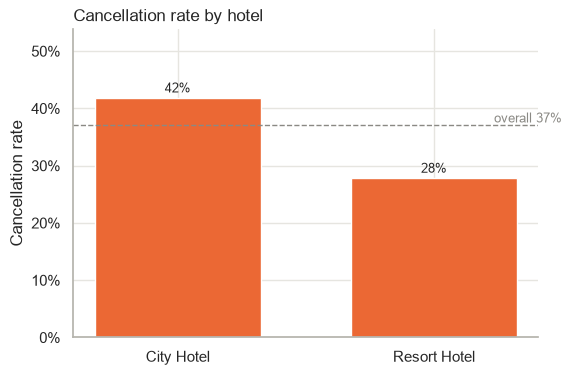

,mean,size
hotel,,
City Hotel,0.418,79162
Resort Hotel,0.278,40046


In [10]:
by_hotel = df.groupby("hotel")["is_canceled"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6, 4))
rate_bar(ax, by_hotel["mean"], "Cancellation rate by hotel")
plt.show()
by_hotel

**Takeaway.** The City Hotel cancels far more often (about 42%) than the Resort Hotel (about 28%). City demand is more short-notice and more often booked through intermediaries. **Action:** apply the preventive policies to the City Hotel first, where the savings are largest.

### 4.2 When do cancellations happen? (arrival month)

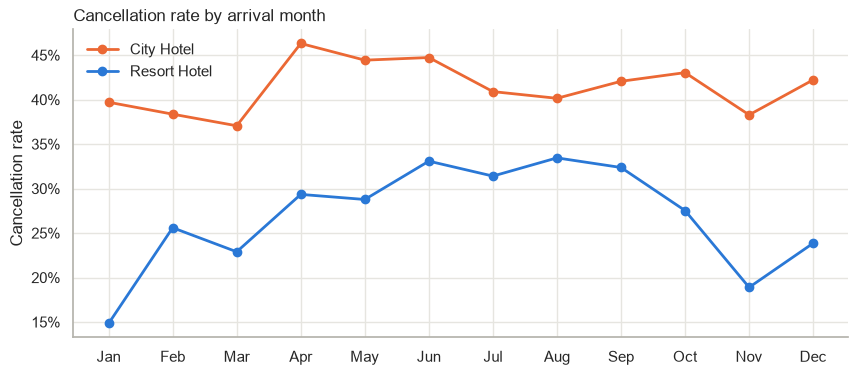

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,0.397,0.148
February,0.384,0.256
March,0.371,0.229
April,0.463,0.293
May,0.444,0.288
June,0.447,0.331
July,0.409,0.314
August,0.401,0.334
September,0.421,0.324


In [11]:
by_month = (df.groupby(["arrival_date_month", "hotel"])["is_canceled"].mean()
              .unstack().reindex(MONTHS))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(12), by_month["City Hotel"], marker="o", lw=2, color=C_CANCEL, label="City Hotel")
ax.plot(range(12), by_month["Resort Hotel"], marker="o", lw=2, color=C_OK, label="Resort Hotel")
ax.set_xticks(range(12), [m[:3] for m in MONTHS])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Cancellation rate")
ax.set_title("Cancellation rate by arrival month", loc="left", fontsize=12)
ax.legend(frameon=False)
plt.show()

by_month   # cancellation rate by arrival month and hotel

**Takeaway.** The City Hotel cancels at a high rate all year (37–46%), peaking for April to June arrivals. The Resort Hotel is clearly seasonal: about 31–34% for June to September arrivals against 15–26% from November to March, and summer is also when an empty resort room costs most. **Action:** keep City Hotel policies in place all year, and make the Resort Hotel's overbooking and deposit rules seasonal (tighter from May to September).

### 4.3 Which channels cancel most?

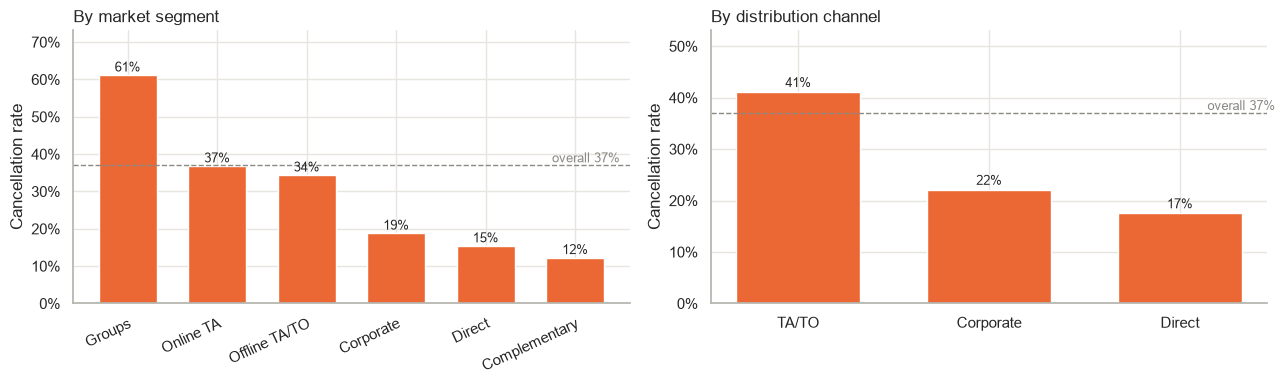

,mean,size
market_segment,,
Undefined,1.000,2
Groups,0.611,19790
Online TA,0.368,56408
Offline TA/TO,0.343,24181
Aviation,0.221,235
Corporate,0.188,5282
Direct,0.154,12582
Complementary,0.122,728


,mean,size
distribution_channel,,
Undefined,0.800,5
TA/TO,0.411,97749
Corporate,0.221,6651
GDS,0.192,193
Direct,0.175,14610


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
seg = df.groupby("market_segment")["is_canceled"].agg(["mean", "size"])
seg = seg[seg["size"] > 500]["mean"].sort_values(ascending=False)   # ignore tiny segments
rate_bar(axes[0], seg, "By market segment", rotate=25)
chan = df.groupby("distribution_channel")["is_canceled"].agg(["mean", "size"])
chan = chan[chan["size"] > 500]["mean"].sort_values(ascending=False)
rate_bar(axes[1], chan, "By distribution channel")
plt.tight_layout(); plt.show()

display(df.groupby("market_segment")["is_canceled"].agg(["mean", "size"]).sort_values("mean", ascending=False))
df.groupby("distribution_channel")["is_canceled"].agg(["mean", "size"]).sort_values("mean", ascending=False)

**Takeaway.** Group bookings cancel most (61%), followed by online and offline travel agents (34–37%). Direct and corporate bookings cancel far less (15–19%). By channel, TA/TO cancels 41% of the time against 17.5% for direct bookings. Intermediaries usually offer free cancellation, so customers book several options and drop the rest, and group blocks are often released. **Action:** steer customers to direct booking (for example, member rates) and ask for deposits or release deadlines on group blocks.

### 4.4 Lead time: how far ahead the booking is made

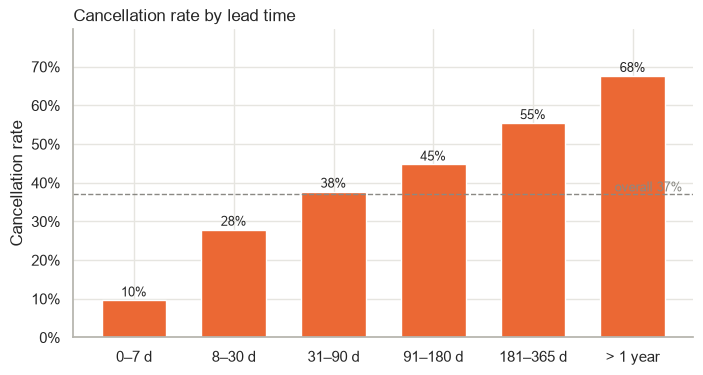

,mean,size
lead_time_band,,
0–7 d,0.096,19635
8–30 d,0.279,18945
31–90 d,0.377,29528
91–180 d,0.447,26420
181–365 d,0.555,21533
> 1 year,0.677,3147


In [13]:
bins = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
labels = ["0–7 d", "8–30 d", "31–90 d", "91–180 d", "181–365 d", "> 1 year"]
df["lead_time_band"] = pd.cut(df["lead_time"], bins=bins, labels=labels)
lt = df.groupby("lead_time_band", observed=True)["is_canceled"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
rate_bar(ax, lt, "Cancellation rate by lead time")
plt.show()
display(df.groupby("lead_time_band", observed=True)["is_canceled"].agg(["mean", "size"]))
df = df.drop(columns="lead_time_band")   # used only for this chart

**Takeaway.** Risk rises steadily with lead time: 10% for last-week bookings, 56% for bookings made 6–12 months ahead and 68% for bookings made more than a year ahead. The longer a customer has to find a better deal or change plans, the more likely they cancel. **Action:** lead time is the natural trigger for asking for a deposit or reconfirming the booking about 30 days before arrival.

### 4.5 Price: do cancelled bookings pay more? (ADR)

mean  median
hotel        is_canceled                
City Hotel   0           106.000 100.000
             1           104.600  99.900
Resort Hotel 0            90.800  72.000
             1           105.800  84.000

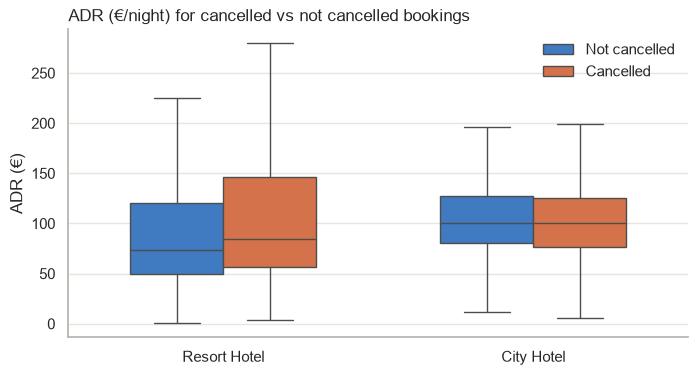

In [14]:
adr_cmp = df.groupby(["hotel", "is_canceled"])["adr"].agg(["mean", "median"]).round(1)
display(adr_cmp)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df[df["adr"] > 0], x="hotel", y="adr", hue="is_canceled",
            palette={0: C_OK, 1: C_CANCEL}, showfliers=False, width=0.6, ax=ax)
ax.set_title("ADR (€/night) for cancelled vs not cancelled bookings", loc="left", fontsize=12)
ax.set_xlabel(""); ax.set_ylabel("ADR (€)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Not cancelled", "Cancelled"], frameon=False)
plt.show()

**Takeaway.** The two hotels behave differently. At the Resort Hotel, cancelled bookings pay about €15 more per night on average (€106 vs €91). Customers who booked expensive dates keep looking for a cheaper price and cancel when they find one. At the City Hotel, prices are the same for both groups (about €105), so price is not what drives City cancellations. **Action:** at the Resort, offer price protection on high-ADR bookings (for example, a small discount or free upgrade in exchange for non-refundable terms). A missed cancellation there costs more than an average room.

### 4.6 Deposit and customer history

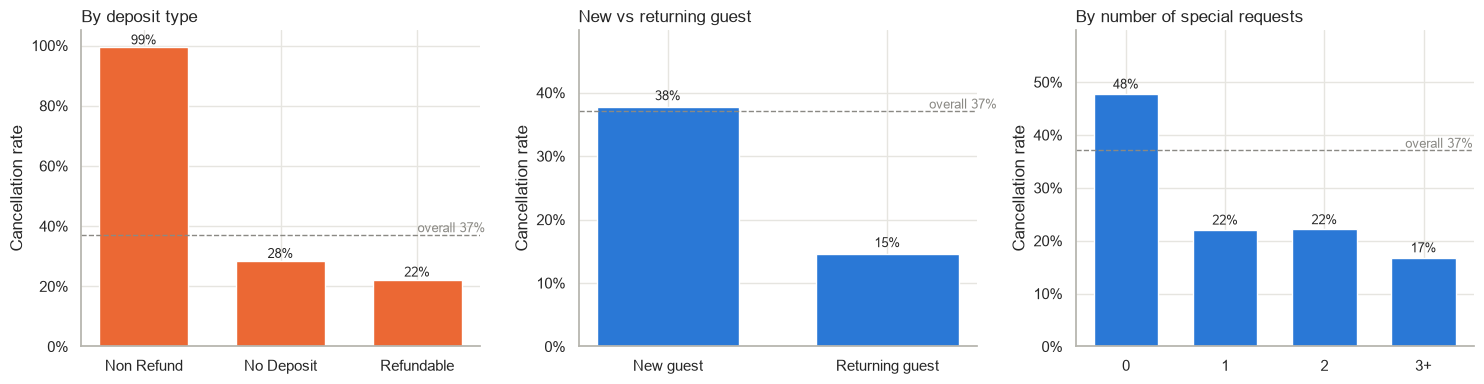

,mean,size
deposit_type,,
No Deposit,0.284,104460
Non Refund,0.994,14586
Refundable,0.222,162


,mean,size
is_repeated_guest,,
New guest,0.378,115454
Returning guest,0.147,3754


,mean,size
special requests (3 = 3 or more),,
0,0.478,70199
1,0.220,33183
2,0.221,12952
3,0.168,2874


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rate_bar(axes[0], df.groupby("deposit_type")["is_canceled"].mean().sort_values(ascending=False),
         "By deposit type")
rate_bar(axes[1], df.groupby("is_repeated_guest")["is_canceled"].mean()
         .rename({0: "New guest", 1: "Returning guest"}), "New vs returning guest", color=C_OK)
rate_bar(axes[2], df.groupby(df["total_of_special_requests"].clip(upper=3))["is_canceled"].mean()
         .rename({3: "3+"}), "By number of special requests", color=C_OK)
plt.tight_layout(); plt.show()
display(df.groupby("deposit_type")["is_canceled"].agg(["mean", "size"]))
display(df.groupby("is_repeated_guest")["is_canceled"].agg(["mean", "size"])
        .rename(index={0: "New guest", 1: "Returning guest"}))
df.groupby(df["total_of_special_requests"].clip(upper=3).rename("special requests (3 = 3 or more)"))["is_canceled"].agg(["mean", "size"])

In [16]:
# Who are the non-refundable bookings? Share of non-refundable bookings by origin, segment and hotel
nr = df[df["deposit_type"] == "Non Refund"]
print(f"Non-refundable bookings: {len(nr):,} (cancellation rate {nr['is_canceled'].mean():.1%})")
profile = pd.concat({col: nr[col].value_counts(normalize=True).head(3)
                     for col in ["country", "market_segment", "hotel"]})
display(profile.rename("share of non-refundable bookings").to_frame())

# The other direction: what share of each hotel's bookings are non-refundable
df.groupby("hotel")["deposit_type"].apply(lambda s: (s == "Non Refund").mean()).rename("share non-refundable").to_frame()

Non-refundable bookings: 14,586 (cancellation rate 99.4%)


share of non-refundable bookings
country        PRT                                       0.972
               GBR                                       0.009
               ESP                                       0.009
market_segment Groups                                    0.629
               Offline TA/TO                             0.343
               Corporate                                 0.023
hotel          City Hotel                                0.882
               Resort Hotel                              0.118

,share non-refundable
hotel,
City Hotel,0.163
Resort Hotel,0.043


**Takeaway.**
- **Non-refundable deposits cancel 99% of the time.** That is counter-intuitive and is a known feature of this dataset. These bookings are almost all Portuguese (97%), mostly Groups (63%) or offline travel agents (34%), and mostly at the City Hotel (88% of them, although they are only 16% of all City Hotel bookings). They look like group or agency room blocks that are reserved and then released. The model will learn this pattern, but the business reading is "block release", not "individual guest changing their mind".
- **Returning guests cancel much less (15% vs 38%), and so do guests with special requests (22% or less vs 48% with none).** A special request (twin beds, high floor) signals that the trip is real and planned. **Action:** the preventive actions should never target returning guests or guests with requests, to protect loyal customers, which is exactly the second error the brief warns about.

## 5. Feature engineering
Every new variable must have a business reason; if we cannot explain why it should predict cancellation, it is not included.

In [17]:
# Total people in the room: families and groups plan differently from solo travellers.
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# Length of stay: longer stays are bigger commitments, often holidays planned well in advance.
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

# Travelling with children: family trips depend on school calendars and are rarely flexible.
df["has_kids"] = ((df["children"] + df["babies"]) > 0).astype(int)

# Guest's personal cancellation history, as a ratio (a single booking with 1 cancellation says more
# than 1 cancellation out of 20 bookings).
prev_total = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
df["prev_cancel_ratio"] = np.where(prev_total > 0, df["previous_cancellations"] / prev_total, 0)

# Price per person: separates a cheap room for four from an expensive room for one.
df["adr_per_person"] = df["adr"] / (df["adults"] + df["children"]).clip(lower=1)

# Weekend-only stay (leisure short break): impulse trips, easy to drop.
df["weekend_only"] = ((df["stays_in_weekend_nights"] > 0) & (df["stays_in_week_nights"] == 0)).astype(int)

# Arrival month as a number and arrival weekday: seasonality and business vs leisure patterns.
df["arrival_month"] = df["arrival_date"].dt.month
df["arrival_weekday"] = df["arrival_date"].dt.dayofweek

# Country grouped: the top 10 origins cover about 84% of bookings; the rest go to "Other" so rare
# countries do not create noisy one-off columns.
top_countries = df["country"].value_counts().nlargest(10).index
df["country_grp"] = df["country"].where(df["country"].isin(top_countries), "Other")

new_feats = ["total_guests", "total_nights", "has_kids", "prev_cancel_ratio",
             "adr_per_person", "weekend_only", "arrival_month", "arrival_weekday"]
df.groupby("is_canceled")[new_feats].mean().T.rename(columns={0: "not cancelled", 1: "cancelled"})

is_canceled,not cancelled,cancelled
total_guests,1.946,2.013
total_nights,3.390,3.488
has_kids,0.081,0.074
prev_cancel_ratio,0.002,0.133
adr_per_person,54.729,55.741
weekend_only,0.067,0.042
arrival_month,6.526,6.597
arrival_weekday,2.963,3.053


In [18]:
prt = df["country"] == "PRT"
print(f"Bookings from Portugal: {prt.mean():.1%} of all bookings")
print(f"Cancellation rate: Portugal {df.loc[prt, 'is_canceled'].mean():.1%} vs other countries {df.loc[~prt, 'is_canceled'].mean():.1%}")
print(f"Bookings covered by the top 10 countries: {df['country'].isin(top_countries).mean():.1%}")

Bookings from Portugal: 40.7% of all bookings
Cancellation rate: Portugal 56.7% vs other countries 23.6%
Bookings covered by the top 10 countries: 84.4%


**Country caveat.** Portugal (PRT) makes up about 40% of bookings and cancels about 57% of the time. Part of this is real: domestic group and agency blocks are often released. Part may come from how the data was recorded, since the dataset's authors note that a guest's nationality is often only confirmed at check-in. We keep the variable because it is captured at booking. We note that it may slightly overstate the model's performance, and that the definition of the field should be checked with the hotel before deployment.

In [19]:
TARGET = "is_canceled"
NUM_FEATS = ["lead_time", "arrival_date_week_number", "arrival_month", "arrival_weekday",
             "stays_in_weekend_nights", "stays_in_week_nights", "total_nights", "adults",
             "children", "babies", "total_guests", "is_repeated_guest", "previous_cancellations",
             "previous_bookings_not_canceled", "prev_cancel_ratio", "days_in_waiting_list", "adr",
             "adr_per_person", "total_of_special_requests",
             "has_agent", "has_company", "has_kids", "weekend_only"]
CAT_FEATS = ["hotel", "meal", "country_grp", "market_segment", "distribution_channel",
             "reserved_room_type", "deposit_type", "customer_type"]
FEATURES = NUM_FEATS + CAT_FEATS

# Not used as features:
# - arrival_date_year: a future booking always has an unseen year, so the model cannot learn from it.
# - arrival_date_day_of_month: no plausible business reason; seasonality is covered by month/week/weekday.
# - country (raw): replaced by country_grp.
print(f"{len(FEATURES)} features: {len(NUM_FEATS)} numeric + {len(CAT_FEATS)} categorical")

31 features: 23 numeric + 8 categorical


## 6. Temporal train / validation / test split
The data covers two years, and in production the model will always predict **future** arrivals from **past** ones. A random split would mix 2017 bookings into training and let the model "see the future" (trends, prices, new channels). We therefore split **by arrival date**:

| Set | Arrivals | Use |
|---|---|---|
| Train | Jul 2015 – Dec 2016 | Fit the models |
| Validation | Jan 2017 – Apr 2017 | Compare models, tune hyperparameters, choose the decision threshold |
| Test | May 2017 – Aug 2017 | Final, untouched evaluation, used **once** |

When a model is chosen, it is refit on train + validation (all data up to April 2017) before the test evaluation, as it would be in production.

In [20]:
df = df.sort_values("arrival_date").reset_index(drop=True)
VALID_START, TEST_START = pd.Timestamp("2017-01-01"), pd.Timestamp("2017-05-01")

train = df[df["arrival_date"] < VALID_START]
valid = df[(df["arrival_date"] >= VALID_START) & (df["arrival_date"] < TEST_START)]
test = df[df["arrival_date"] >= TEST_START]
train_full = df[df["arrival_date"] < TEST_START]          # train + validation

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:6s} {len(part):>7,} rows  ({len(part)/len(df):.0%})  "
          f"{part['arrival_date'].min():%Y-%m-%d} → {part['arrival_date'].max():%Y-%m-%d}  "
          f"cancel rate {part[TARGET].mean():.1%}")

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_full, y_full = train_full[FEATURES], train_full[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

train   78,589 rows  (66%)  2015-07-01 → 2016-12-31  cancel rate 36.2%
valid   18,442 rows  (15%)  2017-01-01 → 2017-04-30  cancel rate 36.5%
test    22,177 rows  (19%)  2017-05-01 → 2017-08-31  cancel rate 40.6%


## 7. Preprocessing
- **Logistic regression and random forest:** one-hot encoding for categoricals (unknown future categories are ignored rather than crashing). For logistic regression we also scale numeric variables so the coefficients are comparable.
- **LightGBM:** handles categoricals natively, so we pass them as the pandas `category` type. This also gives one SHAP value per original variable, which is easier to explain to the business.

In [21]:
def make_ohe_preprocessor(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num, NUM_FEATS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), CAT_FEATS),
    ])

# Category dtype with categories fixed on the training data, so every split is encoded identically
CATEGORIES = {c: sorted(X_full[c].unique()) for c in CAT_FEATS}

def to_lgb(X):
    X = X.copy()
    for c in CAT_FEATS:
        X[c] = pd.Categorical(X[c], categories=CATEGORIES[c])
    return X

## 8. Baseline: logistic regression
An interpretable reference point: any more complex model must beat it clearly to justify itself.

**Imbalance handling.** We use `class_weight="balanced"`, which makes each missed cancellation cost more during training, so the model does not simply favour the majority "not cancelled" class. This reflects the business view that a missed cancellation (an empty room) is the costlier error. We prefer it to oversampling (SMOTE) because it creates no synthetic bookings and keeps probabilities easy to recalibrate. The final decision threshold is then chosen explicitly in section 11.

In [22]:
results = {}   # validation metrics per model

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"AUC-ROC": roc_auc_score(y_true, proba), "F1": f1_score(y_true, pred),
            "Precision": precision_score(y_true, pred), "Recall": recall_score(y_true, pred)}

logreg = Pipeline([
    ("prep", make_ohe_preprocessor(scale=True)),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)),
])
logreg.fit(X_train, y_train)
results["Logistic regression"] = evaluate(y_valid, logreg.predict_proba(X_valid)[:, 1])
pd.DataFrame(results).T

,AUC-ROC,F1,Precision,Recall
Logistic regression,0.854,0.674,0.756,0.609


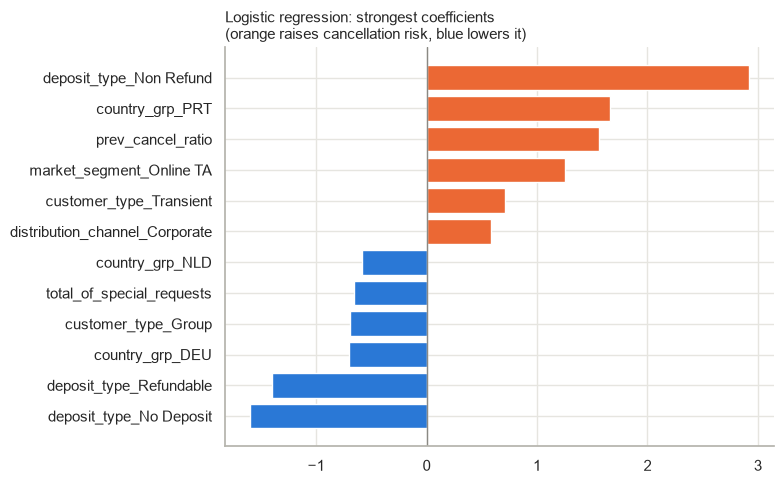

In [23]:
# Interpretability of the baseline: the largest coefficients (on scaled / one-hot features)
coefs = pd.Series(logreg.named_steps["model"].coef_[0],
                  index=logreg.named_steps["prep"].get_feature_names_out())
top = coefs.reindex(coefs.abs().nlargest(12).index).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index.str.replace(r"^(num|cat)__", "", regex=True), top.values,
        color=np.where(top.values > 0, C_CANCEL, C_OK))
ax.axvline(0, color=C_GREY, lw=1)
ax.set_title("Logistic regression: strongest coefficients\n(orange raises cancellation risk, blue lowers it)",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()

The baseline already recovers the EDA story. Non-refundable deposits, Portuguese origin, a history of cancellations and online travel agents push risk up. Special requests, group contracts and the absence of a non-refundable deposit pull it down.

## 9. Other models
Two tree-based models capture non-linear effects (for example, risk that rises with lead time and then plateaus) and interactions (for example, OTA × City Hotel) that a linear model cannot:
- **Random forest:** a robust, low-tuning ensemble.
- **LightGBM:** gradient boosting, usually the strongest choice on tabular data and fast to train.

In [24]:
rf = Pipeline([
    ("prep", make_ohe_preprocessor(scale=False)),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                     n_jobs=-1, random_state=RANDOM_STATE)),
])
rf.fit(X_train, y_train)
results["Random forest"] = evaluate(y_valid, rf.predict_proba(X_valid)[:, 1])

lgbm_default = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1)
lgbm_default.fit(to_lgb(X_train), y_train)
results["LightGBM (default)"] = evaluate(y_valid, lgbm_default.predict_proba(to_lgb(X_valid))[:, 1])

pd.DataFrame(results).T.style.format("{:.3f}").highlight_max(axis=0, color="#d7e6f7")

,AUC-ROC,F1,Precision,Recall
Logistic regression,0.854,0.674,0.756,0.609
Random forest,0.873,0.697,0.786,0.626
LightGBM (default),0.874,0.719,0.769,0.676


Both tree models beat the baseline on AUC, which confirms that non-linear effects matter. LightGBM is the best candidate and is also the fastest to tune, so we optimise it next.

## 10. Hyperparameter optimisation (Optuna)
Optuna searches the space more efficiently than a grid: each trial learns from the previous ones. We optimise **AUC-ROC on the validation period**. AUC measures how well the model ranks risky bookings above safe ones, independently of the threshold, which is chosen afterwards from the business trade-off. We run 40 trials. The output prints the best score after every 10 trials: it is already 0.878 after 10 trials and improves by less than 0.001 over the remaining 30, so the search has levelled off and more trials would not help.

In [25]:
Xtr_lgb, Xva_lgb = to_lgb(X_train), to_lgb(X_valid)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = lgb.LGBMClassifier(**params, class_weight="balanced",
                               random_state=RANDOM_STATE, verbose=-1)
    model.fit(Xtr_lgb, y_train)
    return roc_auc_score(y_valid, model.predict_proba(Xva_lgb)[:, 1])

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)
best_params = {**study.best_params, "subsample_freq": 1}
print(f"Best validation AUC: {study.best_value:.4f}")
best_so_far = pd.Series([t.value for t in study.trials]).cummax()
print("Best AUC so far after 10 / 20 / 30 / 40 trials:", best_so_far.iloc[[9, 19, 29, 39]].round(4).tolist())
best_params

Best validation AUC: 0.8786
Best AUC so far after 10 / 20 / 30 / 40 trials: [0.8781, 0.8781, 0.8782, 0.8786]


{'n_estimators': 300,
 'learning_rate': 0.012830069164560762,
 'num_leaves': 21,
 'min_child_samples': 67,
 'subsample': 0.6763991663354397,
 'colsample_bytree': 0.6161223475728631,
 'reg_lambda': 3.7793726004785584,
 'subsample_freq': 1}

In [26]:
lgbm_tuned = lgb.LGBMClassifier(**best_params, class_weight="balanced",
                                random_state=RANDOM_STATE, verbose=-1)
lgbm_tuned.fit(Xtr_lgb, y_train)
proba_valid_tuned = lgbm_tuned.predict_proba(Xva_lgb)[:, 1]
results["LightGBM (tuned)"] = evaluate(y_valid, proba_valid_tuned)
pd.DataFrame(results).T.style.format("{:.3f}").highlight_max(axis=0, color="#d7e6f7")

,AUC-ROC,F1,Precision,Recall
Logistic regression,0.854,0.674,0.756,0.609
Random forest,0.873,0.697,0.786,0.626
LightGBM (default),0.874,0.719,0.769,0.676
LightGBM (tuned),0.879,0.715,0.770,0.668


## 11. Model comparison, threshold and test results

### 11.1 Choosing the decision threshold
The model outputs a probability. Revenue Management needs a yes/no: *do we act on this booking?* The brief asks us to balance the two errors, so we choose the threshold that **maximises F1 on the validation period**. F1 is the harmonic mean of precision (how many flagged bookings really cancel, which protects loyal guests) and recall (how many cancellations we catch, which protects occupancy). The threshold is fixed on validation and only then applied to test.

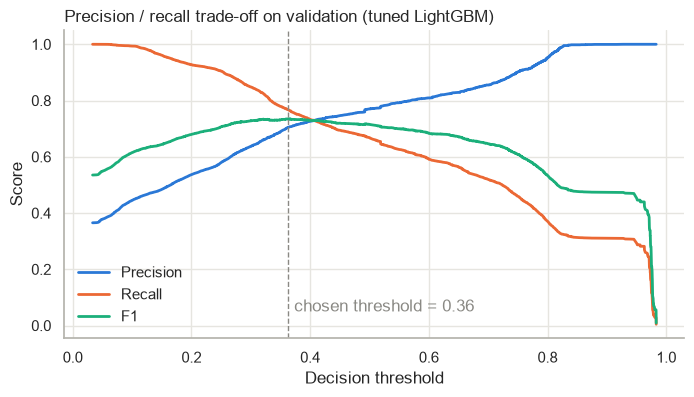

In [27]:
prec, rec, thr = precision_recall_curve(y_valid, proba_valid_tuned)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
BEST_THRESHOLD = float(thr[np.argmax(f1s)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1], color=C_OK, lw=2, label="Precision")
ax.plot(thr, rec[:-1], color=C_CANCEL, lw=2, label="Recall")
ax.plot(thr, f1s, color="#1baf7a", lw=2, label="F1")
ax.axvline(BEST_THRESHOLD, color=C_GREY, ls="--", lw=1)
ax.text(BEST_THRESHOLD + 0.01, 0.05, f"chosen threshold = {BEST_THRESHOLD:.2f}", color=C_GREY)
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title("Precision / recall trade-off on validation (tuned LightGBM)", loc="left", fontsize=12)
ax.legend(frameon=False); plt.show()

### 11.2 Final evaluation on test (May – August 2017)
Every model is refit on all data up to April 2017 and evaluated **once** on the test period. The comparison uses the default 0.5 threshold for all models (fair, like for like). The winning model is also reported at the chosen business threshold.

In [28]:
logreg.fit(X_full, y_full)
rf.fit(X_full, y_full)
lgbm_default.fit(to_lgb(X_full), y_full)
final_model = lgb.LGBMClassifier(**best_params, class_weight="balanced",
                                 random_state=RANDOM_STATE, verbose=-1)
final_model.fit(to_lgb(X_full), y_full)

X_test_lgb = to_lgb(X_test)
test_proba = {
    "Logistic regression": logreg.predict_proba(X_test)[:, 1],
    "Random forest": rf.predict_proba(X_test)[:, 1],
    "LightGBM (default)": lgbm_default.predict_proba(X_test_lgb)[:, 1],
    "LightGBM (tuned)": final_model.predict_proba(X_test_lgb)[:, 1],
}
test_results = {name: evaluate(y_test, p) for name, p in test_proba.items()}
test_results[f"LightGBM (tuned) @ {BEST_THRESHOLD:.2f}"] = evaluate(
    y_test, test_proba["LightGBM (tuned)"], BEST_THRESHOLD)

test_table = pd.DataFrame(test_results).T
test_table.style.format("{:.3f}").highlight_max(axis=0, color="#d7e6f7")

,AUC-ROC,F1,Precision,Recall
Logistic regression,0.824,0.687,0.663,0.714
Random forest,0.836,0.678,0.756,0.615
LightGBM (default),0.836,0.686,0.743,0.637
LightGBM (tuned),0.840,0.684,0.736,0.638
LightGBM (tuned) @ 0.36,0.840,0.705,0.672,0.742


In [29]:
# The chosen threshold in bookings rather than percentages
flagged = test_proba["LightGBM (tuned)"] >= BEST_THRESHOLD
cancelled = y_test.values == 1
print(f"Test bookings: {len(y_test):,}, of which cancelled: {cancelled.sum():,}")
print(f"Flagged at threshold {BEST_THRESHOLD:.2f}: {flagged.sum():,}")
print(f"  flagged and cancelled (caught):        {(flagged & cancelled).sum():,}")
print(f"  flagged but stayed (false alarms):     {(flagged & ~cancelled).sum():,}")
print(f"Not flagged but cancelled (missed):      {(~flagged & cancelled).sum():,}")

Test bookings: 22,177, of which cancelled: 8,998
Flagged at threshold 0.36: 9,932
  flagged and cancelled (caught):        6,675
  flagged but stayed (false alarms):     3,257
Not flagged but cancelled (missed):      2,323


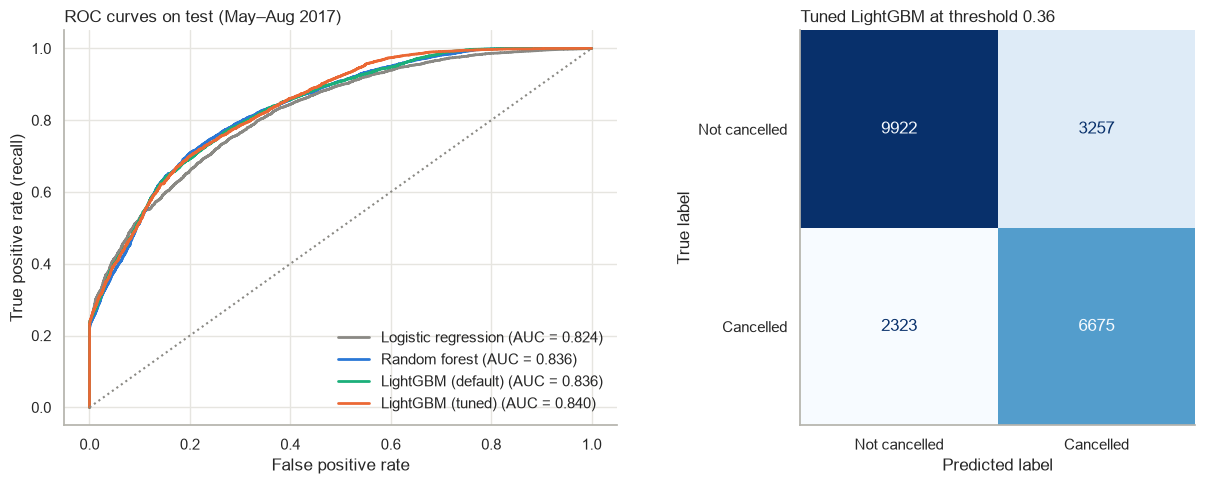

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Logistic regression": C_GREY, "Random forest": C_OK,
          "LightGBM (default)": "#1baf7a", "LightGBM (tuned)": C_CANCEL}
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls=":", color=C_GREY)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves on test (May–Aug 2017)", loc="left", fontsize=12)
axes[0].legend(frameon=False, loc="lower right")

ConfusionMatrixDisplay.from_predictions(
    y_test, (test_proba["LightGBM (tuned)"] >= BEST_THRESHOLD).astype(int),
    display_labels=["Not cancelled", "Cancelled"], cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"Tuned LightGBM at threshold {BEST_THRESHOLD:.2f}", loc="left", fontsize=12)
axes[1].grid(False)
plt.tight_layout(); plt.show()

**Reading the results**
- **Winner: tuned LightGBM.** It has the best AUC on test (0.840, against 0.824 for the logistic baseline and 0.836 for the other tree models), so it is the best at ranking risky bookings above safe ones. That ranking is what Revenue Management uses to decide where to act first. The margin over the baseline is modest (+0.016 AUC), and the gain from tuning is small (+0.004). Most of the value comes from the model family, not the tuning. The logistic regression remains a credible, fully transparent fallback.
- **At the business threshold (0.36), the model catches 74% of cancellations (recall) and 67% of the bookings it flags really cancel (precision), for an F1 of 0.705.** In the four test months, 9,932 bookings are flagged. 6,675 of them do cancel, out of 8,998 cancellations in total. The other 3,257 flagged guests would have turned up, which is why the recommended actions for flagged bookings are soft ones (reconfirmation, an upgrade offer) and not penalties.
- **AUC drops from 0.879 on validation to 0.840 on test.** The test period is the summer peak, with a higher cancellation rate (40.6% vs about 36%) and a different booking mix. This is normal drift. It tells us the model should be retrained regularly (for example, every quarter) on the latest data.

## 12. Interpretability (SHAP)
SHAP breaks each prediction into the contribution of every variable. The **summary plot** shows which variables matter most overall and in which direction. The **waterfall plots** explain individual bookings, which is what a Revenue Manager would see next to a flagged reservation.

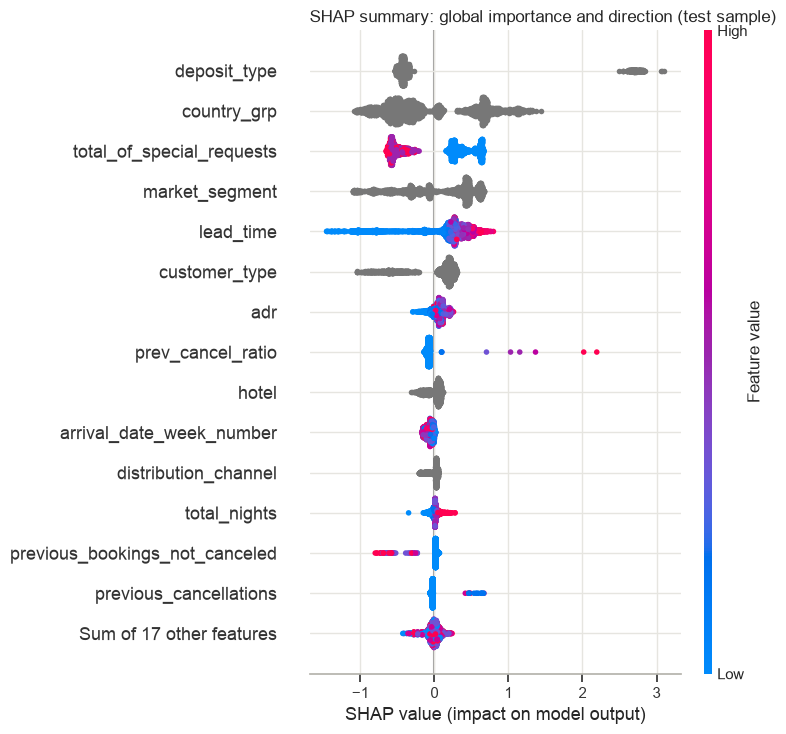

In [31]:
explainer = shap.TreeExplainer(final_model)
X_shap = X_test_lgb.sample(3000, random_state=RANDOM_STATE)   # sample keeps it fast; enough for global patterns
shap_values = explainer(X_shap)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP summary: global importance and direction (test sample)", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

**Reading the summary plot.** Each dot is a booking, and dots to the right push the prediction towards "cancel". Colour is the variable's value (red = high, blue = low; grey = categorical). Values are in log-odds.
- **`deposit_type`** is the strongest single signal. Non-refundable bookings (the cluster far to the right) are the group or agency blocks identified in the EDA.
- **`country_grp`**: Portuguese bookings push risk up, and foreign bookings push it down.
- **`total_of_special_requests`**: any request (red) lowers risk clearly. A guest who asks for something intends to come.
- **`lead_time`**: short lead times (blue) strongly lower risk, and long ones raise it.
- **`market_segment` / `customer_type`**: online travel agents and transient customers raise risk, while contracts and groups without a non-refundable block lower it.
- **`adr`, `prev_cancel_ratio`**: higher prices and a history of cancelling push risk up, which is consistent with the EDA.

In [32]:
# Two concrete bookings: the riskiest and the safest in the sample
proba_shap = final_model.predict_proba(X_shap)[:, 1]
high_i, low_i = int(np.argmax(proba_shap)), int(np.argmin(proba_shap))
# ...and a borderline one, closest to the decision threshold: the most useful case for an operator
mid_i = int(np.argmin(np.abs(proba_shap - BEST_THRESHOLD)))
cols_show = ["hotel", "lead_time", "deposit_type", "market_segment", "customer_type", "country_grp",
             "total_of_special_requests", "previous_cancellations", "adr"]
rows = [high_i, low_i, mid_i]
X_shap.iloc[rows][cols_show].assign(
    predicted_risk=proba_shap[rows], actually_cancelled=y_test.loc[X_shap.index[rows]].values
).set_axis(["High risk", "Low risk", "Borderline"]).T

,High risk,Low risk,Borderline
hotel,City Hotel,Resort Hotel,City Hotel
lead_time,420,231,34
deposit_type,Non Refund,No Deposit,No Deposit
market_segment,Groups,Groups,Online TA
customer_type,Transient,Transient-Party,Transient
country_grp,PRT,GBR,Other
total_of_special_requests,0,1,1
previous_cancellations,0,0,0
adr,90.000,101.000,151.140
predicted_risk,0.983,0.038,0.363


High-risk booking


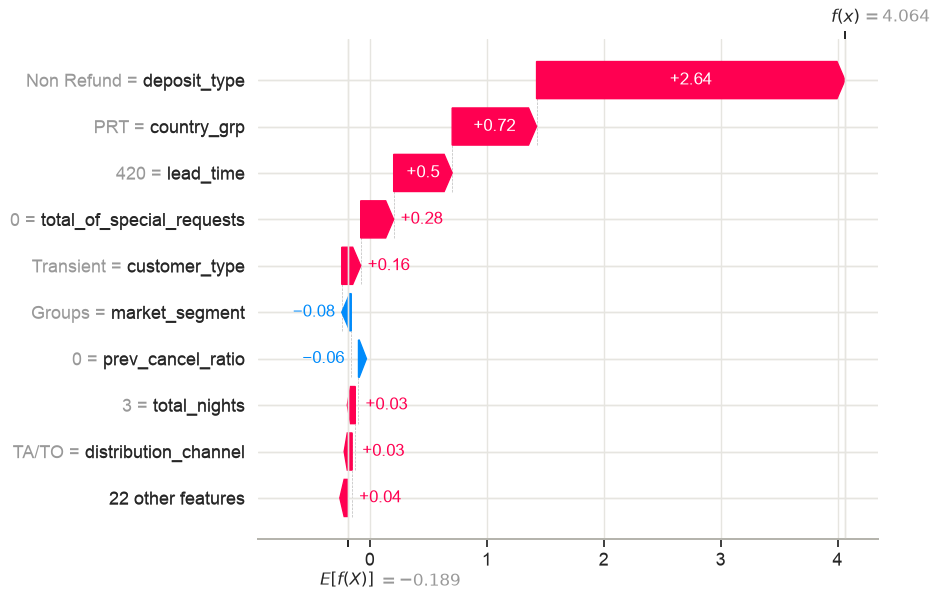

In [33]:
print("High-risk booking")
shap.plots.waterfall(shap_values[high_i], max_display=10)

Low-risk booking


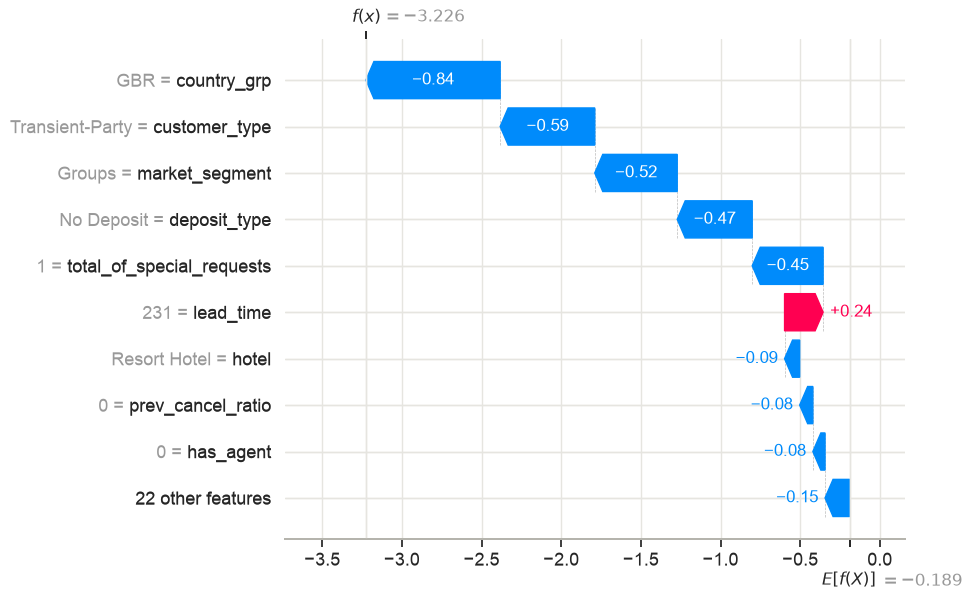

In [34]:
print("Low-risk booking")
shap.plots.waterfall(shap_values[low_i], max_display=10)

Borderline booking: predicted risk 0.36


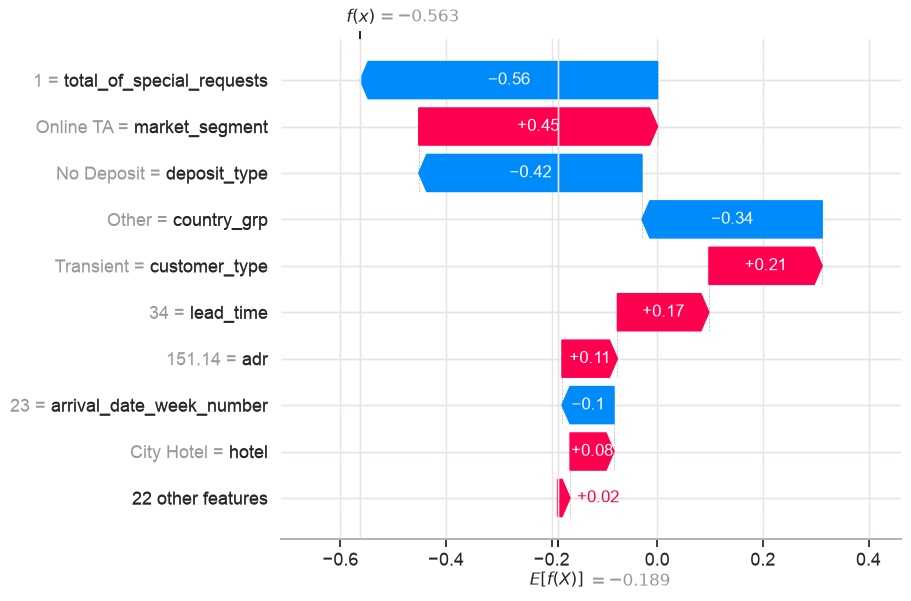

In [35]:
print(f"Borderline booking: predicted risk {proba_shap[mid_i]:.2f}")
shap.plots.waterfall(shap_values[mid_i], max_display=10)

**Reading the waterfall plots** (start from the average prediction at the bottom, then add each variable's push):
- **High-risk booking (98% predicted, did cancel).** A City Hotel group booking from Portugal, made 420 days ahead, with a non-refundable deposit and no special requests. The deposit type alone adds most of the risk. This is a typical group block that gets released.
- **Low-risk booking (4% predicted, did not cancel).** A British Transient-Party booking at the Resort Hotel with no deposit and one special request. Even though it was booked 231 days ahead (which adds risk), its origin, customer type and special request outweigh the lead time.
- **Borderline booking (36%, right at the threshold).** A City Hotel booking through an online travel agent, 34 days ahead, at €151 per night. The OTA channel and the transient customer type push risk up, while the special request and the absence of a deposit pull it down. Cases like this are where a light-touch action, such as a reconfirmation email, costs little and settles the uncertainty.

## 13. Conclusions

**1. Which bookings are most likely to cancel, and why.** The highest-risk profile is a booking made **months in advance**, through **groups or travel agents**, from **Portugal**, at the **City Hotel**, with **no special requests**. The most extreme case is a **non-refundable group block**, which is released almost every time. Long lead times leave room to find a better offer. Intermediaries make cancelling free and easy. No special requests signals a speculative booking. The lowest-risk profile is a returning or direct or corporate guest, booking close to arrival, who has asked for something specific.

**2. The model.** A tuned LightGBM, trained on data up to April 2017 and tested on May–August 2017, reaches **AUC 0.84**. At the chosen threshold it catches **74% of cancellations with 67% precision**. It uses only information available when the booking is made. Five leaking variables were excluded, including one (`required_car_parking_spaces`) that is not obvious at first sight.

**3. Proposed use.**
- **Score every booking when it is made**, and again as its details change, and give Revenue Management a daily list of flagged bookings (risk ≥ 0.36).
- **Flagged individual bookings:** send a reconfirmation email about 30 days before arrival, and offer a discounted upgrade in exchange for non-refundable conditions. Both are low-cost and respectful of the guest.
- **Group and agency blocks:** set release deadlines and ask for partial deposits. The model shows these are the most predictable cancellations.
- **Overbooking:** the sum of predicted probabilities for a given night is the expected number of cancellations. Use it to set a per-night overbooking level instead of a flat percentage, tighter at the City Hotel and in the Resort Hotel's summer season.
- **Protect loyal customers:** never apply restrictive measures to returning guests or to guests with special requests, who cancel far less.

**4. Next steps.**
- Put a € value on each error with Revenue Management (the cost of an empty room vs the cost of an annoyed guest) and move from the F1 threshold to a cost-minimising one.
- Confirm with the hotel when `country` and parking are recorded, to rule out any remaining leakage.
- Retrain quarterly to absorb seasonality and drift, and monitor AUC on each new month.
- Run an A/B test of the preventive actions to measure how many cancellations they actually avoid.